# **Multimodal RAG (PDF With Images)**

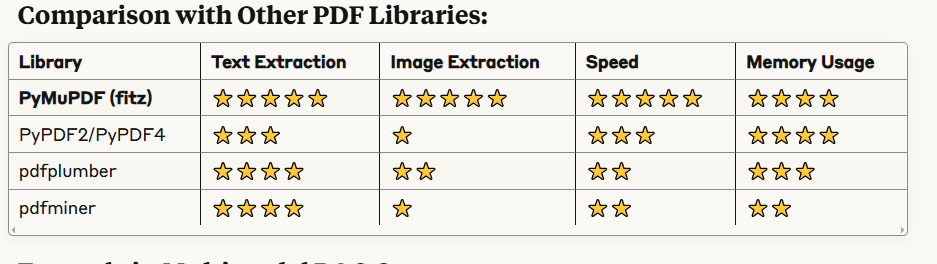

In [3]:
!pip install PyMuPDF langchain -U langchain-text-splitters langchain-community faiss-cpu langchain-openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 42.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 580.5/580.5 kB 16.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 39.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 30.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 54.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 71.0 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
  Attempting uninstall: langchain
    Found existing installation: langchain 1.4.8
    Uninstalling langchain-1.4.8:
      Successfully uninstalled langchain-1.4.8
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
!pip install -q langchain-google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.0.0 which is incompatible.


In [16]:
import pymupdf as fitz
from langchain_core.documents import Document
from transformers import CLIPProcessor, CLIPModel
from PIL import Image
import torch
import numpy as np
from langchain.chat_models import init_chat_model
from langchain_core.prompts import PromptTemplate
from langchain_core.messages import HumanMessage
from sklearn.metrics.pairwise import cosine_similarity

import os
from dotenv import load_dotenv
load_dotenv()

import base64
import io
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS

In [6]:
from google.colab import userdata

# Setting up the Environment
os.environ["OPENAI_API_KEY"] = userdata.get("MultiModalAPI")

In [7]:
import getpass
import os

# Fallback: Manually input the API key if Colab secrets key is invalid
openai_key = getpass.getpass("Enter your OpenAI API Key (starts with sk-): ")
if openai_key.strip():
    os.environ["OPENAI_API_KEY"] = openai_key
    print("API Key updated successfully!")
else:
    print("No key entered, keeping existing configuration.")

Enter your OpenAI API Key (starts with sk-): ··········
API Key updated successfully!


In [8]:
import getpass
import os
from langchain.chat_models import init_chat_model

# Securely input your actual OpenAI API key
openai_key = getpass.getpass("Enter your OpenAI API Key (starts with sk-): ")
if openai_key.strip() and not openai_key.startswith("Query:"):
    os.environ["OPENAI_API_KEY"] = openai_key.strip()
    print("API Key updated successfully!")

    # Re-initialize the model to apply the new credentials
    llm = init_chat_model("openai:gpt-4.1")
    print("LLM client re-initialized with the new API key!")
else:
    print("Invalid input detected. Please make sure to enter only the API key (starts with sk-).")

Enter your OpenAI API Key (starts with sk-): ··········
API Key updated successfully!
LLM client re-initialized with the new API key!


In [50]:
import os
import getpass
from langchain_google_genai import ChatGoogleGenerativeAI

# Ensure environment variables are correctly mapped
for env_key in ["GOOGLE_API_KEY", "GEMINI_API_KEY"]:
    if env_key in os.environ:
        del os.environ[env_key]

# Use verified user_input or ask secure credential input
if 'user_input' not in globals() or not user_input:
    user_input = getpass.getpass("Please paste your actual Gemini API key (starts with AIzaSy): ").strip()

if user_input:
    os.environ["GOOGLE_API_KEY"] = user_input
    os.environ["GEMINI_API_KEY"] = user_input
    print("\n[Success] API Key has been registered!")

    # Use the active Gemini 2.5 Flash model
    llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash", temperature=0)
    print("[Success] LLM successfully initialized with ChatGoogleGenerativeAI (gemini-3.8-flash)!")
else:
    print("\n[Error] Invalid key format.")


[Success] API Key has been registered!
[Success] LLM successfully initialized with ChatGoogleGenerativeAI (gemini-2.5-flash)!


In [51]:
# Initialize the Clip Model for Unified Embeddings
# Responsible for converting both text into embeddings and image into embeddings
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
# clip_processor: required for converting into required format
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [11]:
# Evaluating the Clip Model
clip_model.eval()

CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1

In [30]:
### Embedding functions
def embed_image(image_data):
    """Embed image using CLIP"""
    if isinstance(image_data, str):
        image = Image.open(image_data).convert("RGB")
    else:  # If PIL Image
        image = image_data

    inputs = clip_processor(images=image, return_tensors="pt")
    with torch.no_grad():
        features = clip_model.get_image_features(**inputs)
        # If it returns a BaseModelOutputWithPooling instead of a raw Tensor
        if not isinstance(features, torch.Tensor):
            features = features.pooler_output
        # Normalize embeddings to unit vector
        features = features / features.norm(dim=-1, keepdim=True)
        return features.squeeze().numpy()

def embed_text(text):
    """Embed text using CLIP."""
    inputs = clip_processor(
        text=text,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=77  # CLIP's max token length
    )
    with torch.no_grad():
        features = clip_model.get_text_features(**inputs)
        # If it returns a BaseModelOutputWithPooling instead of a raw Tensor
        if not isinstance(features, torch.Tensor):
            features = features.pooler_output
        # Normalize embeddings
        features = features / features.norm(dim=-1, keepdim=True)
        return features.squeeze().numpy()

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Processing out Pdf data**

In [17]:
## Process PDF
pdf_path=r"/content/drive/MyDrive/multimodal_sample.pdf"
doc=fitz.open(pdf_path)

In [18]:
# Storage for all documents and embeddings
all_docs = []
all_embeddings = []
image_data_store = {}  # Store actual image data for LLM

# Text splitter
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)
print(splitter)

In [27]:
doc

closed Document('/content/drive/MyDrive/multimodal_sample.pdf')

**Processing Text**

In [29]:
## Re-open the document to ensure it's not closed when running this cell again
doc = fitz.open(pdf_path)

for i,page in enumerate(doc):
    ## process text
    text=page.get_text()
    if text.strip():
        ##create temporary document for splitting
        temp_doc = Document(page_content=text, metadata={"page": i, "type": "text"})
        text_chunks = splitter.split_documents([temp_doc])

        #Embed each chunk using CLIP
        for chunk in text_chunks:
            embedding = embed_text(chunk.page_content)
            all_embeddings.append(embedding)
            all_docs.append(chunk)



    ## process images
    ##Three Important Actions:

    ##Convert PDF image to PIL format
    ##Store as base64 for GPT-4V (which needs base64 images)
    ##Create CLIP embedding for retrieval

    for img_index, img in enumerate(page.get_images(full=True)):
        try:
            xref = img[0]
            base_image = doc.extract_image(xref)
            image_bytes = base_image["image"]

            # Convert to PIL Image
            pil_image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

            # Create unique identifier
            image_id = f"page_{i}_img_{img_index}"

            # Store image as base64 for later use with GPT-4V
            buffered = io.BytesIO()
            pil_image.save(buffered, format="PNG")
            img_base64 = base64.b64encode(buffered.getvalue()).decode()
            image_data_store[image_id] = img_base64

            # Embed image using CLIP
            embedding = embed_image(pil_image)
            all_embeddings.append(embedding)

            # Create document for image
            image_doc = Document(
                page_content=f"[Image: {image_id}]",
                metadata={"page": i, "type": "image", "image_id": image_id}
            )
            all_docs.append(image_doc)

        except Exception as e:
            print(f"Error processing image {img_index} on page {i}: {e}")
            continue

doc.close()

Error processing image 0 on page 0: 'BaseModelOutputWithPooling' object has no attribute 'norm'


In [31]:
# Re-initialize storage
all_docs = []
all_embeddings = []
image_data_store = {}

# Open the PDF safely
doc = fitz.open(pdf_path)

for i, page in enumerate(doc):
    # 1. Process Text Chunks
    text = page.get_text()
    if text.strip():
        temp_doc = Document(page_content=text, metadata={"page": i, "type": "text"})
        text_chunks = splitter.split_documents([temp_doc])

        for chunk in text_chunks:
            embedding = embed_text(chunk.page_content)
            all_embeddings.append(embedding)
            all_docs.append(chunk)

    # 2. Process Images
    for img_index, img in enumerate(page.get_images(full=True)):
        try:
            xref = img[0]
            base_image = doc.extract_image(xref)
            image_bytes = base_image["image"]

            # Convert to PIL Image
            pil_image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

            # Create unique identifier
            image_id = f"page_{i}_img_{img_index}"

            # Store image as base64 for later use
            buffered = io.BytesIO()
            pil_image.save(buffered, format="PNG")
            img_base64 = base64.b64encode(buffered.getvalue()).decode()
            image_data_store[image_id] = img_base64

            # Embed image using the fixed embed_image
            embedding = embed_image(pil_image)
            all_embeddings.append(embedding)

            # Create document for image
            image_doc = Document(
                page_content=f"[Image: {image_id}]",
                metadata={"page": i, "type": "image", "image_id": image_id}
            )
            all_docs.append(image_doc)

        except Exception as e:
            print(f"Error processing image {img_index} on page {i}: {e}")
            continue

doc.close()
print(f"Successfully processed and embedded {len(all_docs)} total items (text and images)!")

Successfully processed and embedded 2 total items (text and images)!


In [32]:
all_docs

[Document(metadata={'page': 0, 'type': 'text'}, page_content='Annual Revenue Overview\nThis document summarizes the revenue trends across Q1, Q2, and Q3. As illustrated in the chart\nbelow, revenue grew steadily with the highest growth recorded in Q3.\nQ1 showed a moderate increase in revenue as new product lines were introduced. Q2 outperformed\nQ1 due to marketing campaigns. Q3 had exponential growth due to global expansion.'),
 Document(metadata={'page': 0, 'type': 'image', 'image_id': 'page_0_img_0'}, page_content='[Image: page_0_img_0]')]

In [23]:
# Create unified FAISS vector store with CLIP embeddings
embeddings_array = np.array(all_embeddings)
embeddings_array

array([], dtype=float64)

In [24]:
(all_docs,embeddings_array)

([], array([], dtype=float64))

In [33]:
# Recreate the numpy embeddings array from the newly populated all_embeddings
import numpy as np
embeddings_array = np.array(all_embeddings)

# Create custom FAISS index since we now have the populated precomputed embeddings
vector_store = FAISS.from_embeddings(
    text_embeddings=[(doc.page_content, emb) for doc, emb in zip(all_docs, embeddings_array)],
    embedding=None,  # We're using precomputed embeddings
    metadatas=[doc.metadata for doc in all_docs]
)
print("FAISS vector store successfully initialized with precomputed text and image embeddings!")

FAISS vector store successfully initialized with precomputed text and image embeddings!


In [ ]:
print(vector_store)

In [ ]:
# Initialize GPT-4 Vision model
llm = init_chat_model("openai:gpt-4.1")
llm

In [ ]:
def retrieve_multimodal(query, k=5):
    """Unified retrieval using CLIP embeddings for both text and images."""
    # Embed query using CLIP
    query_embedding = embed_text(query)

    # Search in unified vector store
    results = vector_store.similarity_search_by_vector(
        embedding=query_embedding,
        k=k
    )

    return results

In [ ]:
def create_multimodal_message(query, retrieved_docs):
    """Create a message with both text and images for GPT-4V."""
    content = []

    # Add the query
    content.append({
        "type": "text",
        "text": f"Question: {query}\n\nContext:\n"
    })

    # Separate text and image documents
    text_docs = [doc for doc in retrieved_docs if doc.metadata.get("type") == "text"]
    image_docs = [doc for doc in retrieved_docs if doc.metadata.get("type") == "image"]

    # Add text context
    if text_docs:
        text_context = "\n\n".join([
            f"[Page {doc.metadata['page']}]: {doc.page_content}"
            for doc in text_docs
        ])
        content.append({
            "type": "text",
            "text": f"Text excerpts:\n{text_context}\n"
        })

    # Add images
    for doc in image_docs:
        image_id = doc.metadata.get("image_id")
        if image_id and image_id in image_data_store:
            content.append({
                "type": "text",
                "text": f"\n[Image from page {doc.metadata['page']}]:\n"
            })
            content.append({
                "type": "image_url",
                "image_url": {
                    "url": f"data:image/png;base64,{image_data_store[image_id]}"
                }
            })

    # Add instruction
    content.append({
        "type": "text",
        "text": "\n\nPlease answer the question based on the provided text and images."
    })

    return HumanMessage(content=content)

In [35]:
def retrieve_multimodal(query, k=5):
    """Unified retrieval using CLIP embeddings for both text and images."""
    query_embedding = embed_text(query)
    results = vector_store.similarity_search_by_vector(
        embedding=query_embedding,
        k=k
    )
    return results

def create_multimodal_message(query, retrieved_docs):
    """Create a message with both text and images for the LLM."""
    content = []
    content.append({
        "type": "text",
        "text": f"Question: {query}\n\nContext:\n"
    })

    text_docs = [doc for doc in retrieved_docs if doc.metadata.get("type") == "text"]
    image_docs = [doc for doc in retrieved_docs if doc.metadata.get("type") == "image"]

    if text_docs:
        text_context = "\n\n".join([
            f"[Page {doc.metadata['page']}]: {doc.page_content}"
            for doc in text_docs
        ])
        content.append({
            "type": "text",
            "text": f"Text excerpts:\n{text_context}\n"
        })

    for doc in image_docs:
        image_id = doc.metadata.get("image_id")
        if image_id and image_id in image_data_store:
            content.append({
                "type": "text",
                "text": f"\n[Image from page {doc.metadata['page']}]:\n"
            })
            content.append({
                "type": "image_url",
                "image_url": {
                    "url": f"data:image/png;base64,{image_data_store[image_id]}"
                }
            })

    content.append({
        "type": "text",
        "text": "\n\nPlease answer the question based on the provided text and images."
    })
    return HumanMessage(content=content)

def multimodal_pdf_rag_pipeline(query):
    """Main pipeline for multimodal RAG."""
    context_docs = retrieve_multimodal(query, k=5)
    message = create_multimodal_message(query, context_docs)
    response = llm.invoke([message])

    print(f"\nRetrieved {len(context_docs)} documents:")
    for doc in context_docs:
        doc_type = doc.metadata.get("type", "unknown")
        page = doc.metadata.get("page", "?")
        if doc_type == "text":
            preview = doc.page_content[:100] + "..." if len(doc.page_content) > 100 else doc.page_content
            print(f"  - Text from page {page}: {preview}")
        else:
            print(f"  - Image from page {page}")
    print("\n")
    return response.content

In [52]:
if __name__ == "__main__":
    queries = [
        "What does the chart on page 1 show about revenue trends?",
        "Summarize the main findings from the document",
        "What visual elements are present in the document?"
    ]

    for query in queries:
        print(f"\nQuery: {query}")
        print("-" * 50)
        try:
            answer = multimodal_pdf_rag_pipeline(query)
            print(f"Answer:\n{answer}")
        except Exception as e:
            print(f"An error occurred during execution: {e}")
        print("=" * 70)


Query: What does the chart on page 1 show about revenue trends?
--------------------------------------------------

Retrieved 2 documents:
  - Text from page 0: Annual Revenue Overview
This document summarizes the revenue trends across Q1, Q2, and Q3. As illust...
  - Image from page 0


Answer:
[{'type': 'text', 'text': 'Based on the text and the chart provided (on Page 0 / the first page):\n\n* **Steady Upward Growth:** The chart shows three ascending bars (blue, green, red) representing an increasing trend across Q1, Q2, and Q3.\n* **Q1 (Blue bar):** Starts at the lowest level of the three quarters.\n* **Q2 (Green bar):** Shows higher revenue than Q1.\n* **Q3 (Red bar):** Reaches the tallest bar, representing the highest revenue and most significant growth due to global expansion.', 'extras': {'signature': 'ErMJCrAJAWkUfRNmn0q19oJCWIk3O/OsOP0DLt/6c+B33rS9lxQnuQiCPJQvTEO1VdzMlkTAl+ASEzu40VmAPL/wNdwe19iUARLFQqQqdx47bq+d/cH+4eW0u8tcglqwcff9p/snIOxrA+opbLXnPbQdmS1qqpM6IFmSbuMQPhWYWuR0j